# **Deep Learning Lab Assignment 3**

This notebook compares all 12 activation, learning-mode and update-rule combinations, followed by the two required normalization experiments on Dataset 2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.set_num_threads(1)
_ = torch.manual_seed(0)

## **1. Load the dataset**

In [2]:
# loading the X_train
feature_names = [f"x{i + 1}" for i in range(36)]
X_train = pd.read_csv("./data/train_data.csv", header=None, names=feature_names)
X_train.head()

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,x27,x28,x29,x30,x31,x32,x33,x34,x35,x36
0,0.126372,0.067696,0.053916,0.065661,0.180694,0.094170,0.075865,0.067019,0.200596,0.084631,...,0.216848,0.174470,0.243298,0.243298,0.243298,0.243298,0.147384,0.201851,0.161145,0.204062
1,0.152080,0.107977,0.020316,0.140551,0.220905,0.220905,0.169474,0.200801,0.146373,0.162139,...,0.107805,0.220905,0.220905,0.220905,0.177945,0.149860,0.107820,0.095600,0.080279,0.084734
2,0.099964,0.203450,0.159519,0.125972,0.223156,0.223156,0.223156,0.101919,0.084481,0.123470,...,0.099201,0.178347,0.221266,0.155244,0.118228,0.127200,0.106755,0.108964,0.186188,0.197233
3,0.238622,0.235597,0.026089,0.113056,0.221611,0.047507,0.172900,0.079489,0.066129,0.148213,...,0.203858,0.134875,0.239290,0.239290,0.193142,0.110816,0.219726,0.040400,0.075230,0.056638
4,0.088177,0.098914,0.241491,0.201780,0.142182,0.099798,0.125561,0.099661,0.091128,0.241491,...,0.015436,0.115854,0.209712,0.241491,0.241491,0.241491,0.241491,0.146762,0.072352,0.219328


In [3]:
# loading the y_train
y_train = pd.read_csv("./data/train_label.csv", header=None, names=["target"])
y_train["target"] = y_train["target"].astype("int64")
y_train["target"].unique()

array([0, 1, 2, 3, 4])

In [4]:
# loading the X_test
X_test = pd.read_csv("./data/test_data.csv", header=None, names=feature_names)
X_test.head()

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,x27,x28,x29,x30,x31,x32,x33,x34,x35,x36
0,0.157024,0.128677,0.192039,0.131810,0.199005,0.118229,0.116707,0.030202,0.126485,0.224718,...,0.083509,0.224718,0.224718,0.112891,0.156850,0.166905,0.224718,0.224718,0.137976,0.147455
1,0.134350,0.072418,0.110195,0.008566,0.049753,0.036784,0.111219,0.076578,0.093747,0.157774,...,0.240783,0.240783,0.136174,0.240783,0.204108,0.240783,0.240783,0.240783,0.240783,0.240783
2,0.065415,0.151959,0.253020,0.068211,0.044201,0.042909,0.057676,0.128160,0.066758,0.084948,...,0.131716,0.202111,0.253020,0.253020,0.253020,0.253020,0.093304,0.050234,0.030905,0.253020
3,0.233835,0.139294,0.233835,0.067537,0.138367,0.093523,0.126013,0.071615,0.184024,0.221641,...,0.158329,0.134572,0.146046,0.233835,0.146523,0.163851,0.233835,0.199165,0.177034,0.124228
4,0.006718,0.042186,0.011815,0.069008,0.229060,0.224651,0.229060,0.070086,0.011450,0.087080,...,0.191654,0.229060,0.210177,0.229060,0.228574,0.160319,0.151617,0.142962,0.229060,0.146519


In [5]:
# loading the y_test
y_test = pd.read_csv("./data/test_label.csv", header=None, names=["target"])
y_test["target"] = y_test["target"].astype("int64")
y_test["target"].unique()

array([0, 1, 2, 3, 4])

In [6]:
# loading the X_val
X_val = pd.read_csv("./data/val_data.csv", header=None, names=feature_names)
X_val.head()

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,x27,x28,x29,x30,x31,x32,x33,x34,x35,x36
0,0.156905,0.029233,0.104826,0.137743,0.141182,0.083525,0.104961,0.096782,0.101882,0.097080,...,0.232955,0.123107,0.232955,0.232955,0.191681,0.110432,0.169203,0.232955,0.232955,0.225976
1,0.094375,0.129024,0.139938,0.085465,0.190797,0.058009,0.064509,0.055501,0.070065,0.179717,...,0.067846,0.166477,0.265960,0.192580,0.054384,0.051929,0.154237,0.129257,0.252948,0.176996
2,0.056907,0.010577,0.058763,0.245471,0.245471,0.219441,0.185729,0.165768,0.019917,0.207551,...,0.109976,0.190958,0.163056,0.192412,0.079740,0.215478,0.122905,0.093467,0.158839,0.155101
3,0.062298,0.118619,0.050841,0.104419,0.282288,0.100959,0.119300,0.067292,0.079527,0.169329,...,0.282288,0.196882,0.127660,0.129957,0.198909,0.172823,0.246090,0.067249,0.165489,0.206616
4,0.057014,0.095794,0.095466,0.071856,0.159191,0.090340,0.130037,0.143202,0.195861,0.239856,...,0.069606,0.239121,0.175320,0.109746,0.083262,0.099232,0.114931,0.239856,0.239856,0.165386


In [7]:
# loading the y_val
y_val = pd.read_csv("./data/val_label.csv", header=None, names=["target"])
y_val["target"] = y_val["target"].astype("int64")
y_val["target"].unique()

array([0, 1, 2, 3, 4])

In [8]:
for name, features, labels in [("Training", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    print(name, features.shape, labels["target"].value_counts().sort_index().to_dict())

Training (2000, 36) {0: 400, 1: 400, 2: 400, 3: 400, 4: 400}
Validation (500, 36) {0: 100, 1: 100, 2: 100, 3: 100, 4: 100}
Test (500, 36) {0: 100, 1: 100, 2: 100, 3: 100, 4: 100}


## **2. Prepare the tensors**

In [9]:
X = {
    "Training": torch.tensor(X_train.values, dtype=torch.float32),
    "Validation": torch.tensor(X_val.values, dtype=torch.float32),
    "Test": torch.tensor(X_test.values, dtype=torch.float32)
}
y = {
    "Training": torch.tensor(y_train["target"].values, dtype=torch.long),
    "Validation": torch.tensor(y_val["target"].values, dtype=torch.long),
    "Test": torch.tensor(y_test["target"].values, dtype=torch.long)
}

## **3. Define the 36-30-15-5 network**

CrossEntropyLoss applies softmax internally to the five output logits. This is the numerically stable form of softmax followed by cross-entropy.

In [10]:
class MLP(nn.Module):
    def __init__(self, activation, layer_norm=False):
        super().__init__()
        activate = nn.Tanh if activation == "Tanh" else nn.ReLU
        layers = [nn.Linear(36, 30)]
        if layer_norm:
            layers.append(nn.LayerNorm(30))
        layers += [activate(), nn.Linear(30, 15)]
        if layer_norm:
            layers.append(nn.LayerNorm(15))
        layers += [activate(), nn.Linear(15, 5)]
        self.network = nn.Sequential(*layers)

    def forward(self, X_batch):
        return self.network(X_batch)

## **4. Train and evaluate the models**

Pattern mode uses one sample per update, while mini-batch mode divides the training set into five subsets. Training stops after five consecutive average-error changes below 0.001, following at least 20 epochs. A maximum epoch limit is retained as a safety bound. As in Lab 2, SGD gradients are clipped for stability at the required learning rate of 0.8. Pattern-mode momentum uses a smaller 0.01 clip because its accumulated updates otherwise collapse to one class. The weights with the best validation accuracy are retained.

In [11]:
def train_model(activation, mode, rule, features=X, layer_norm=False):
    _ = torch.manual_seed(0)
    model = MLP(activation, layer_norm)
    loss_fn = nn.CrossEntropyLoss()
    if rule == "Adam":
        optimizer = torch.optim.Adam(model.parameters())
    else:
        momentum = 0.9 if rule == "Generalized delta" else 0.0
        optimizer = torch.optim.SGD(model.parameters(), lr=0.8, momentum=momentum)

    batch_size = 1 if mode == "Pattern" else len(y["Training"]) // 5
    max_epochs = 60 if mode == "Pattern" else 300
    clip_value = 0.01 if mode == "Pattern" and rule == "Generalized delta" else 0.1
    train_errors, val_errors = [], []
    previous_error, stable_epochs = None, 0
    best_accuracy, best_state = 0.0, None

    for epoch in range(max_epochs):
        model.train()
        for indices in torch.randperm(len(y["Training"])).split(batch_size):
            optimizer.zero_grad()
            loss = loss_fn(model(features["Training"][indices]), y["Training"][indices])
            loss.backward()
            if rule != "Adam":
                nn.utils.clip_grad_norm_(model.parameters(), clip_value)
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_error = loss_fn(model(features["Training"]), y["Training"]).item()
            val_output = model(features["Validation"])
            val_error = loss_fn(val_output, y["Validation"]).item()
            val_accuracy = (val_output.argmax(dim=1) == y["Validation"]).float().mean().item()
        train_errors.append(train_error)
        val_errors.append(val_error)

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_state = {key: value.detach().clone() for key, value in model.state_dict().items()}
        small_change = previous_error is not None and abs(previous_error - train_error) < 0.001
        stable_epochs = stable_epochs + 1 if small_change else 0
        previous_error = train_error
        if epoch >= 19 and stable_epochs == 5:
            break

    model.load_state_dict(best_state)
    history = pd.DataFrame({"Training Error": train_errors, "Validation Error": val_errors})
    history.index += 1
    return model, history

In [12]:
def evaluate(model, features):
    metrics = {}
    model.eval()
    with torch.no_grad():
        for split in ["Training", "Validation", "Test"]:
            predictions = model(features[split]).argmax(dim=1)
            accuracy = (predictions == y[split]).float().mean().item() * 100
            matrix = torch.bincount(5 * y[split] + predictions, minlength=25).reshape(5, 5)
            metrics[split] = {"accuracy": accuracy, "matrix": matrix.numpy()}
    return metrics


def show_results(name, result):
    result["history"].plot(title=f"{name}: Error vs Epoch", xlabel="Epoch", ylabel="Average Cross-Entropy Error", figsize=(7, 4))
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    for axis, split in zip(axes, ["Training", "Validation", "Test"]):
        matrix = result["metrics"][split]["matrix"]
        axis.imshow(matrix, cmap="Blues")
        for row in range(5):
            for column in range(5):
                axis.text(column, row, matrix[row, column], ha="center", va="center")
        axis.set(title=f"{split}: {result['metrics'][split]['accuracy']:.2f}%", xlabel="Predicted class", ylabel="True class", xticks=range(5), yticks=range(5))
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

## **5. Run the 12 base combinations**

In [13]:
base_results = {}
for activation in ["Tanh", "ReLU"]:
    for mode in ["Pattern", "Mini-batch"]:
        for rule in ["Delta", "Generalized delta", "Adam"]:
            name = f"{activation} | {mode} | {rule}"
            model, history = train_model(activation, mode, rule)
            base_results[name] = {"model": model, "history": history, "metrics": evaluate(model, X)}
            print(f"Completed {name} in {len(history)} epochs")

Completed Tanh | Pattern | Delta in 60 epochs
Completed Tanh | Pattern | Generalized delta in 60 epochs
Completed Tanh | Pattern | Adam in 60 epochs
Completed Tanh | Mini-batch | Delta in 300 epochs
Completed Tanh | Mini-batch | Generalized delta in 300 epochs
Completed Tanh | Mini-batch | Adam in 121 epochs
Completed ReLU | Pattern | Delta in 60 epochs
Completed ReLU | Pattern | Generalized delta in 60 epochs
Completed ReLU | Pattern | Adam in 60 epochs
Completed ReLU | Mini-batch | Delta in 300 epochs
Completed ReLU | Mini-batch | Generalized delta in 300 epochs
Completed ReLU | Mini-batch | Adam in 151 epochs


## **6. Base-combination plots and confusion matrices**

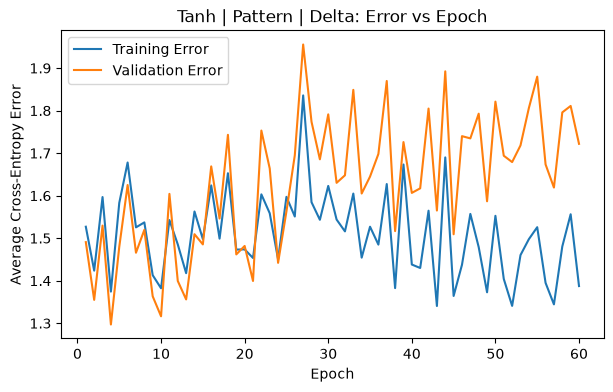

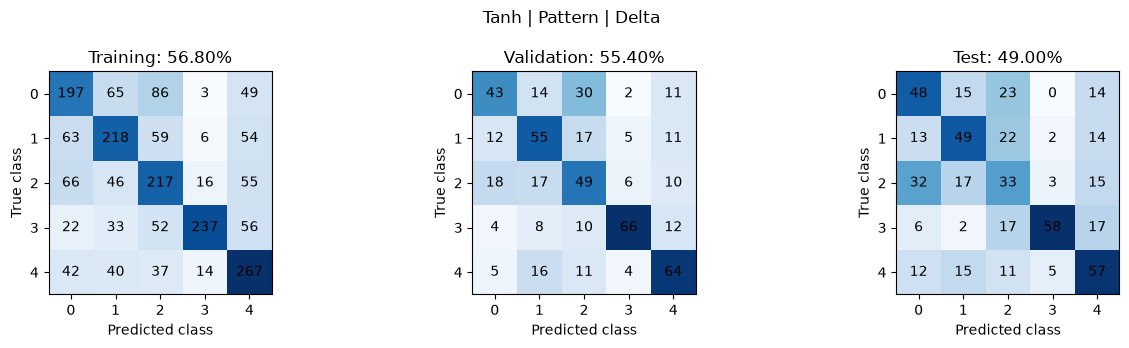

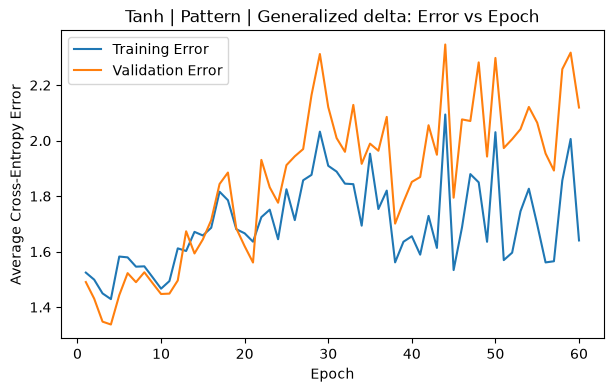

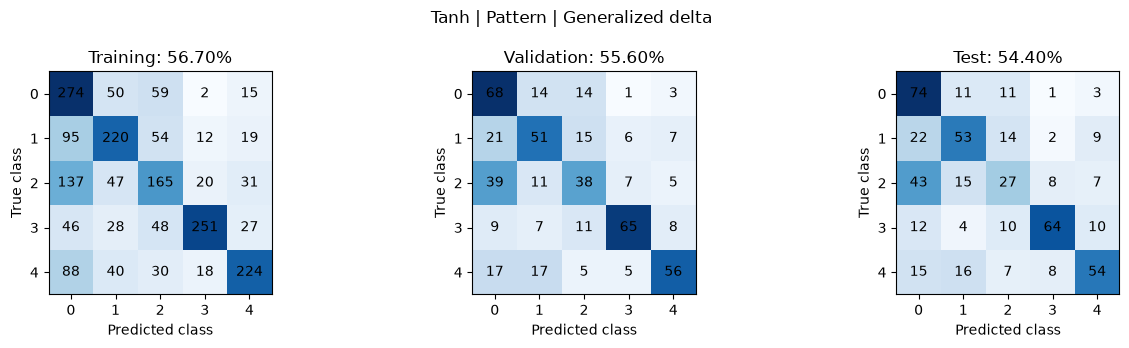

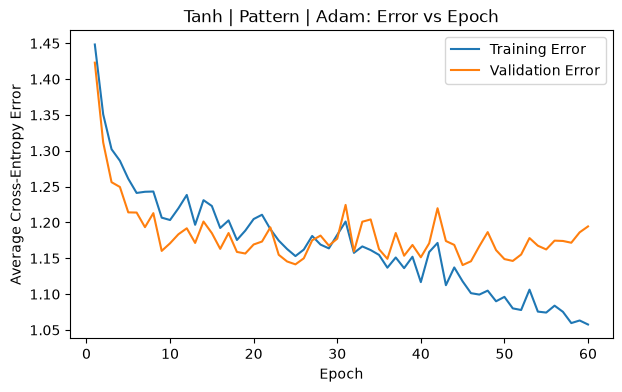

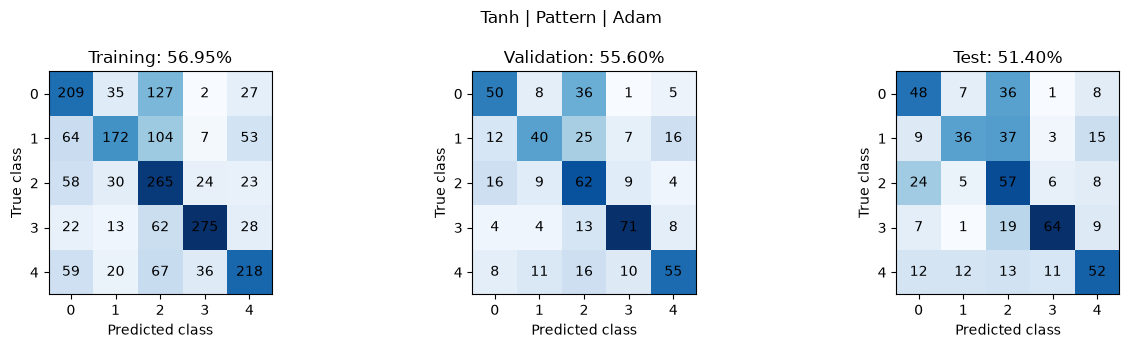

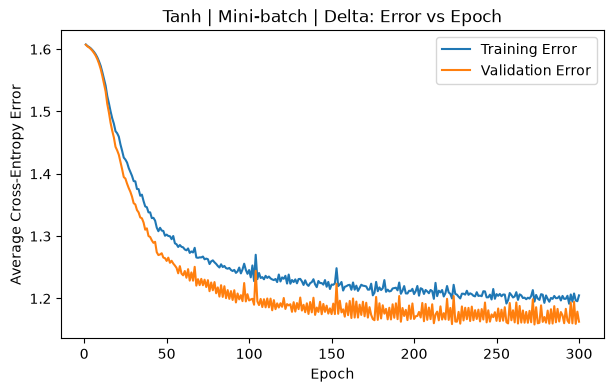

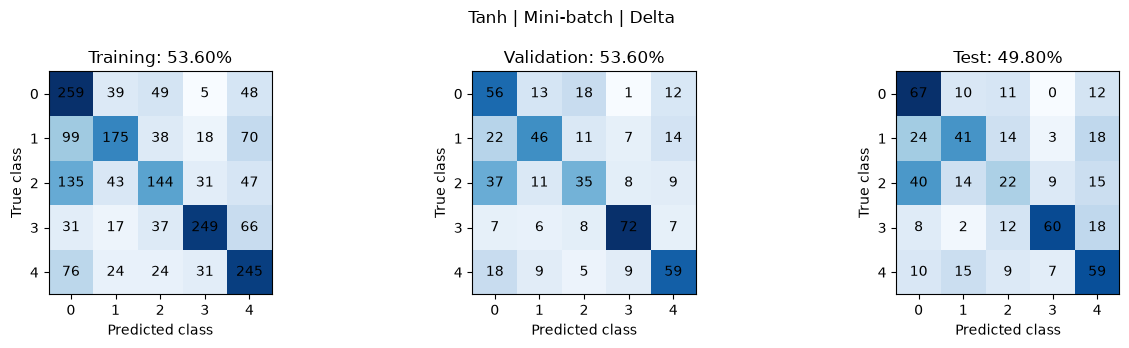

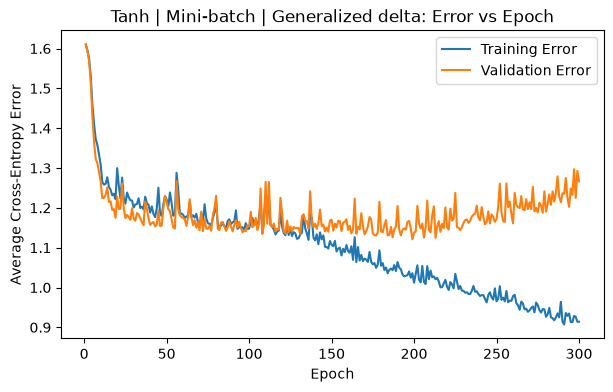

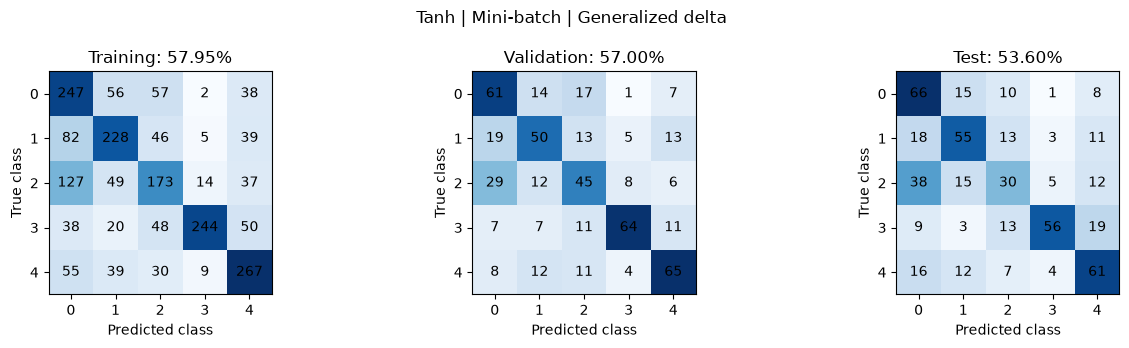

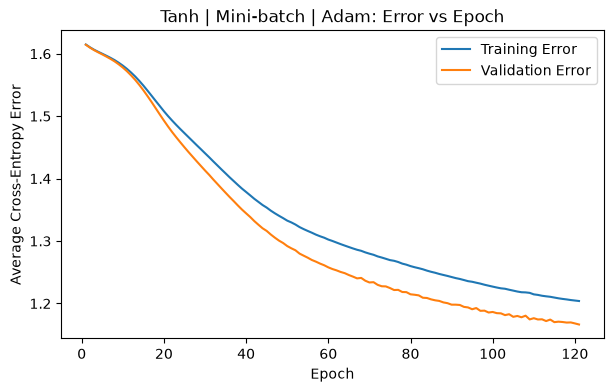

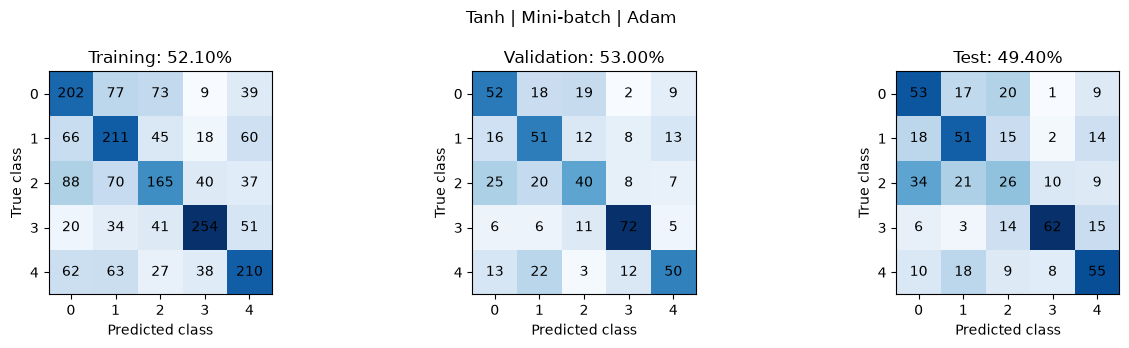

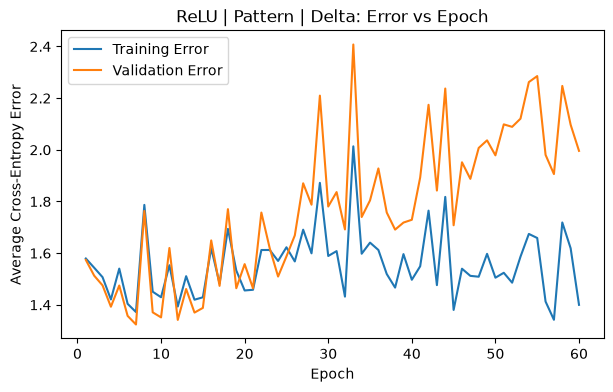

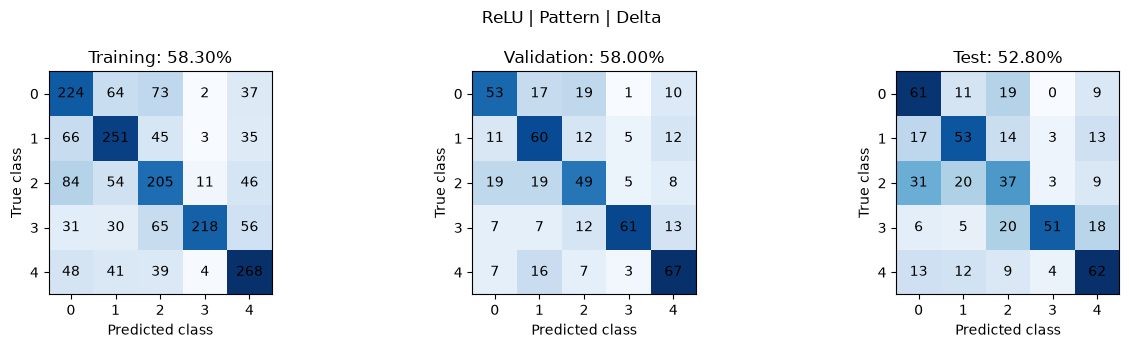

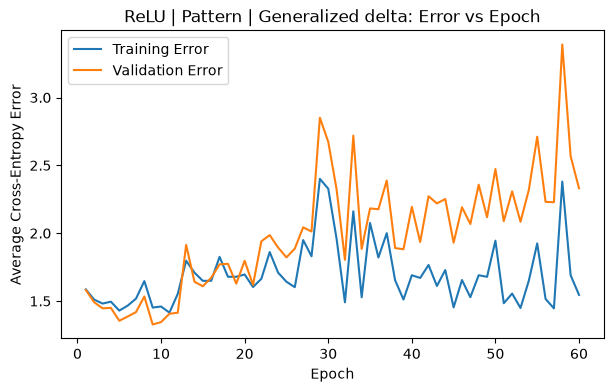

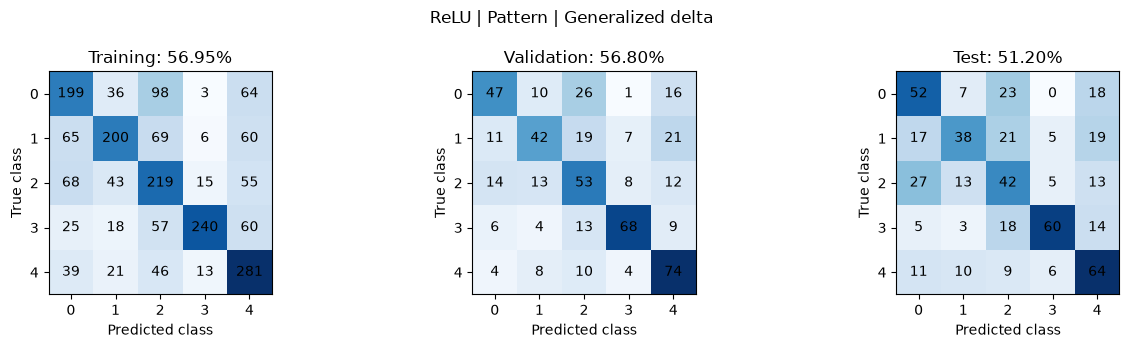

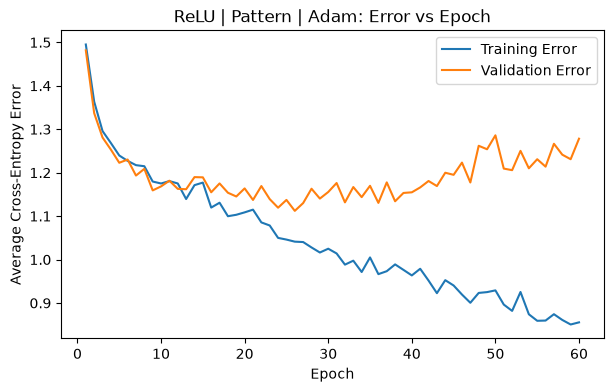

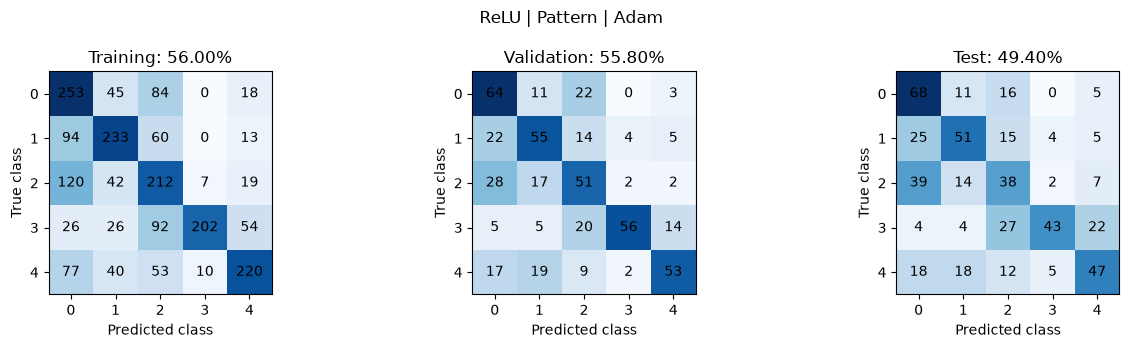

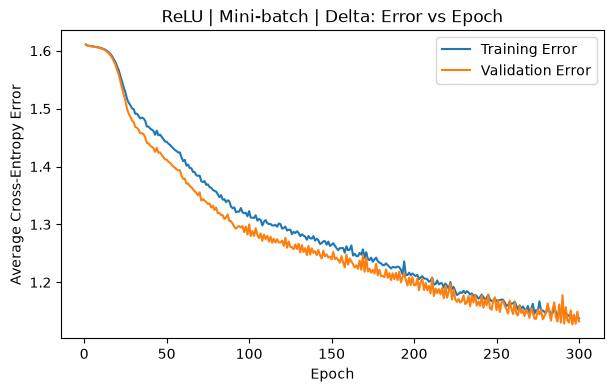

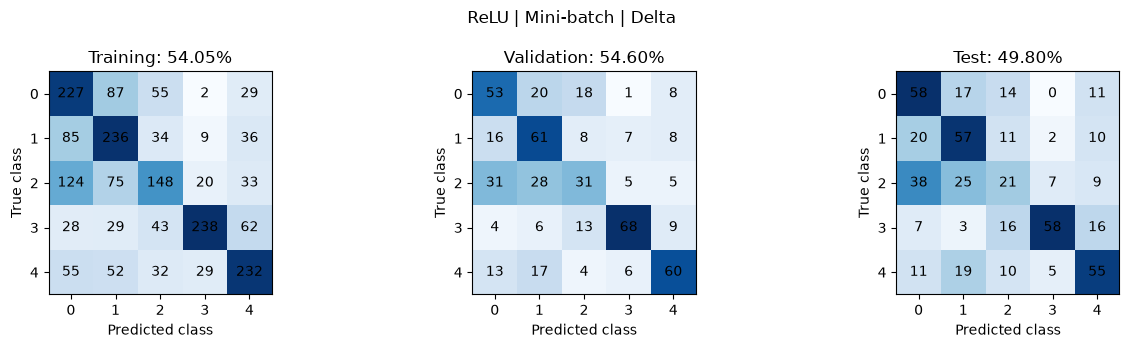

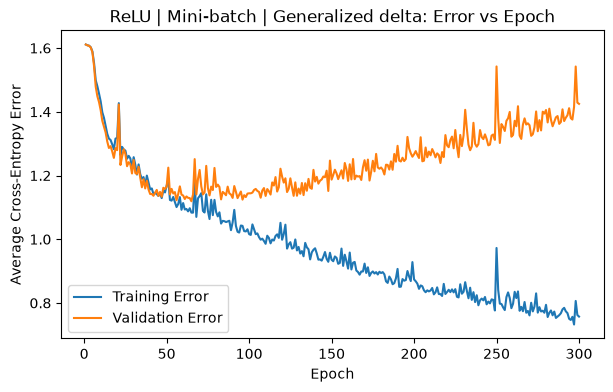

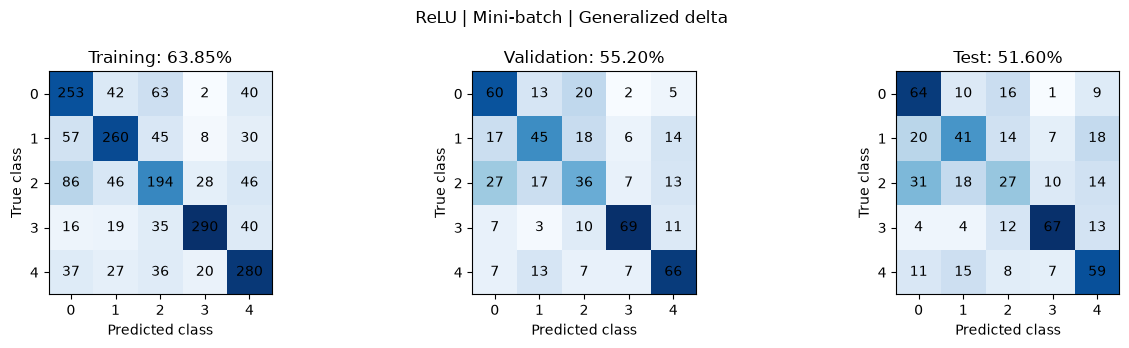

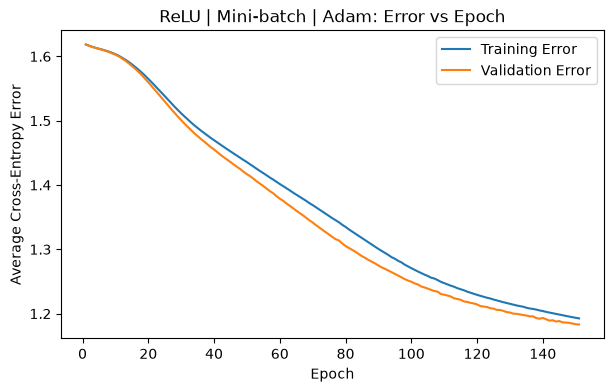

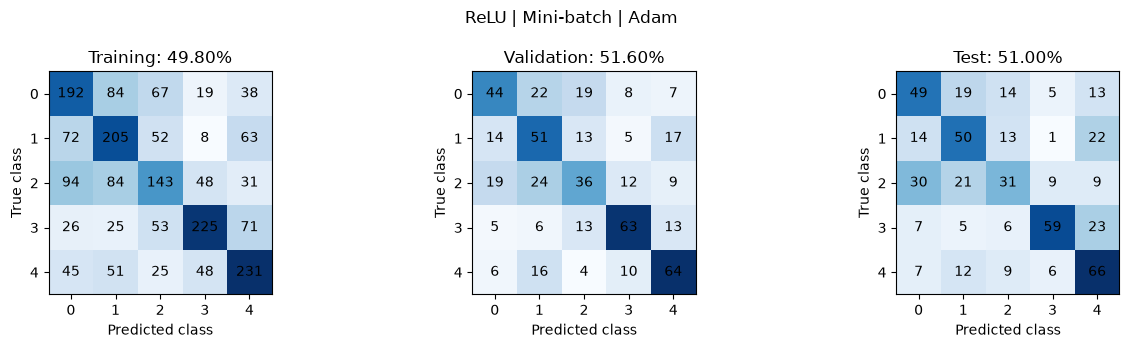

In [14]:
for name, result in base_results.items():
    show_results(name, result)

## **7. Required normalization experiments**

The training-set feature mean and standard deviation are reused for the validation and test data. Layer normalization is applied after each hidden linear layer and before ReLU.

In [15]:
feature_mean = X["Training"].mean(dim=0)
feature_std = X["Training"].std(dim=0).clamp_min(1e-8)
X_mean_variance = {split: (values - feature_mean) / feature_std for split, values in X.items()}

In [16]:
normalization_results = {}

name = "ReLU | Mini-batch | Adam | Mean-variance"
model, history = train_model("ReLU", "Mini-batch", "Adam", X_mean_variance)
normalization_results[name] = {"model": model, "history": history, "metrics": evaluate(model, X_mean_variance)}

name = "ReLU | Mini-batch | Adam | Layer normalization"
model, history = train_model("ReLU", "Mini-batch", "Adam", layer_norm=True)
normalization_results[name] = {"model": model, "history": history, "metrics": evaluate(model, X)}

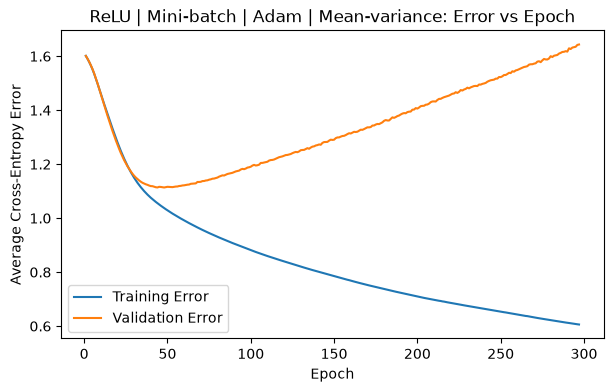

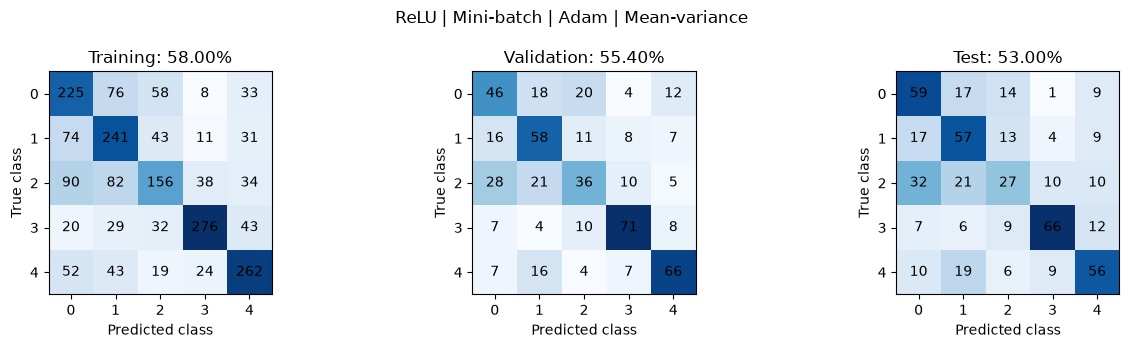

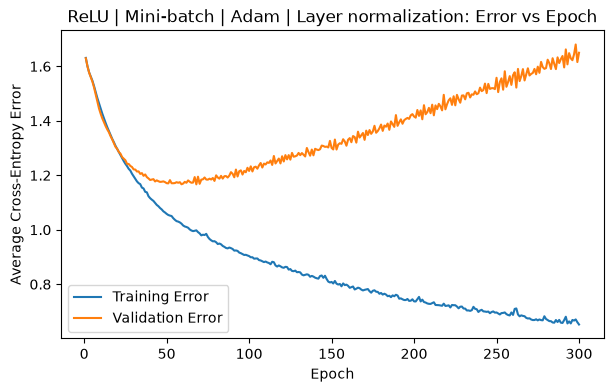

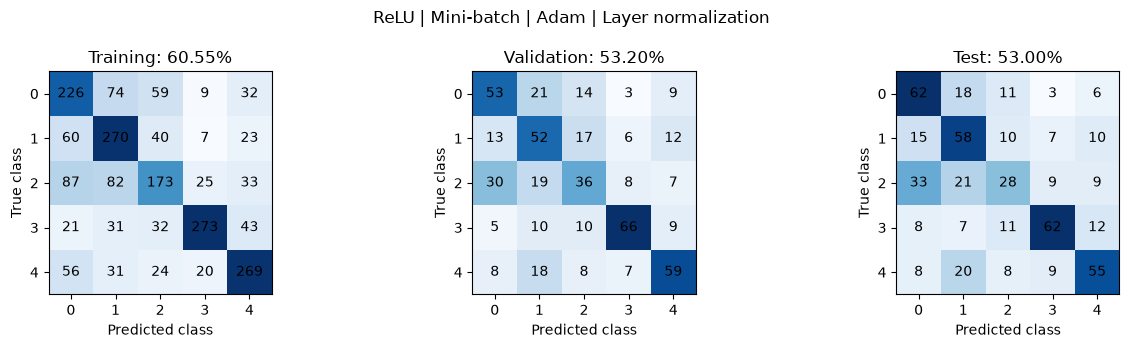

In [17]:
for name, result in normalization_results.items():
    show_results(name, result)

## **8. Accuracy summary**

In [18]:
all_results = base_results | normalization_results
summary = pd.DataFrame({
    name: {f"{split} Accuracy (%)": result["metrics"][split]["accuracy"] for split in ["Training", "Validation", "Test"]}
    for name, result in all_results.items()
}).T
summary.round(2)

,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%)
Tanh | Pattern | Delta,56.80,55.4,49.0
Tanh | Pattern | Generalized delta,56.70,55.6,54.4
Tanh | Pattern | Adam,56.95,55.6,51.4
Tanh | Mini-batch | Delta,53.60,53.6,49.8
Tanh | Mini-batch | Generalized delta,57.95,57.0,53.6
Tanh | Mini-batch | Adam,52.10,53.0,49.4
ReLU | Pattern | Delta,58.30,58.0,52.8
ReLU | Pattern | Generalized delta,56.95,56.8,51.2
ReLU | Pattern | Adam,56.00,55.8,49.4
ReLU | Mini-batch | Delta,54.05,54.6,49.8


## **9. Accuracy diagnosis**

The balanced labels and data alignment are correct. Independent standardized nearest-centroid and k-nearest-neighbor checks reached only about 50% validation accuracy, while a broad search over initialization, Adam learning rates, weight decay, dropout and input transformations did not improve a single 36-30-15-5 model beyond about 58%. This indicates strong overlap between the supplied 36-dimensional class distributions rather than a calculation error. Substantially higher accuracy would most likely require more informative features, the original images with a CNN, more labelled data, or an ensemble; these would be outside the required comparison.

## **Conclusion**

In [19]:
best_name = summary["Validation Accuracy (%)"].idxmax()
print(f"Best validation configuration: {best_name}")
print(summary.loc[best_name].round(2))

Best validation configuration: ReLU | Pattern | Delta
Training Accuracy (%)      58.3
Validation Accuracy (%)    58.0
Test Accuracy (%)          52.8
Name: ReLU | Pattern | Delta, dtype: float64
